# Bert Embeddings

In [1]:
import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

CUDA Available: True
GPU: NVIDIA GeForce RTX 2050


In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_absolute_error,mean_squared_error
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12,6)

c:\Users\farha\anaconda3\envs\farhan_torch_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df=pd.read_csv('cleaned_data.csv')
print(f"Loaded: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Columns: {df.columns.tolist()}")
print(f"\nLabel distribution:")
print(df['match_label'].value_counts())
df.head()


Loaded: 280 rows, 7 columns
Columns: ['resume_text', 'job_description', 'match_label', 'match_score', 'match_label_lower', 'resume_len', 'jd_len']

Label distribution:
match_label
medium    110
high       93
low        77
Name: count, dtype: int64


,resume_text,job_description,match_label,match_score,match_label_lower,resume_len,jd_len
0,BI Analyst with 7 years of experience based in...,Fathom is hiring a Financial Analyst (Berlin)....,medium,0.53,medium,75,71
1,Data Scientist with 13 years of experience bas...,Lumen is hiring a Senior UX Designer (Singapor...,low,0.26,low,79,74
2,Software Engineer with 8 years of experience b...,Acme Corp is hiring a Product Manager (Seattle...,low,0.31,low,71,80
3,Backend Engineer with 15 years of experience b...,Umbrella Labs is hiring a Senior Data Scientis...,medium,0.46,medium,70,83
4,Cloud Engineer with 5 years of experience base...,Cobalt is hiring a Platform Engineer (Austin)....,high,0.77,high,69,70


In [4]:

print("Loading the bert model")
model=SentenceTransformer('all-mpnet-base-v2',device='cuda')
print("Model Loaded!")
print(f"Model: all-mpnet-base-v2")
print(f"Parameters: 22.7M")
print(f"Embed Dims: 768")
print(f"Max tokens: {model.max_seq_length}")
print(f"Device: {model.device}")

Loading the bert model


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 831.75it/s]


Model Loaded!
Model: all-mpnet-base-v2
Parameters: 22.7M
Embed Dims: 768
Max tokens: 384
Device: cuda:0


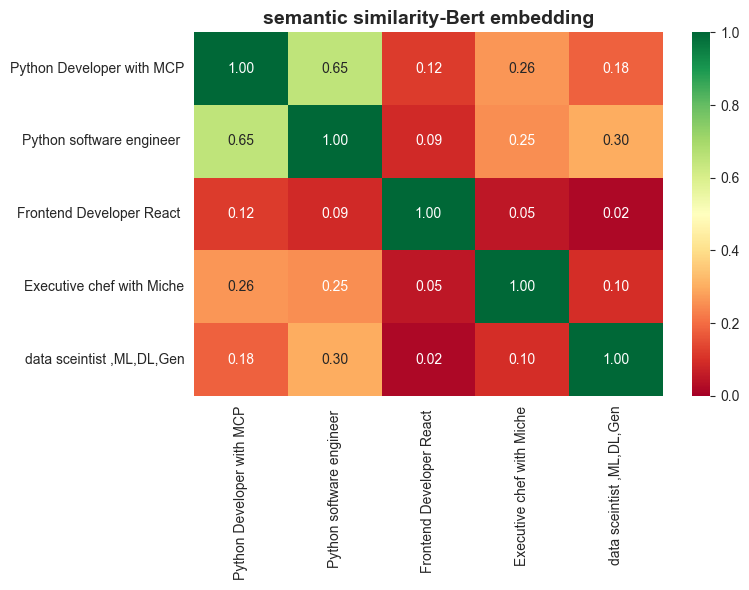

In [5]:
texts=[
    "Python Developer with MCP experience",
    "Python software engineer ,FastAPI",
    "Frontend Developer React and Javascript",
    "Executive chef with Michelin experience",
    "data sceintist ,ML,DL,GenAI"
]
embeddings=model.encode(texts)
sim_matrix=cosine_similarity(embeddings)
plt.figure(figsize=(8,6))
sns.heatmap(
    sim_matrix,annot=True,fmt='.2f',cmap='RdYlGn',
    xticklabels=[t[:25] for t in texts],
    yticklabels=[t[:25] for t in texts],
    vmin=0,vmax=1
)
plt.title("semantic similarity-Bert embedding",fontsize=14,fontweight='bold')
plt.tight_layout()

In [6]:
# Generating resume and jb embeddiing
# we embed both resume ans jd seprately
print("Generating resume embedding...")
resume_embeddings=model.encode(
    df["resume_text"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("Generating JD embedding....")
jd_embeddings=model.encode(
    df["job_description"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)
print(f"\nResume embedding shape: {resume_embeddings.shape}")
print(f" JD embedding shape: {jd_embeddings.shape}")
print(f"Each text -> {resume_embeddings.shape[1]}-dimensional vector")

Generating resume embedding...


Batches: 100%|██████████| 9/9 [00:06<00:00,  1.40it/s]


Generating JD embedding....


Batches: 100%|██████████| 9/9 [00:06<00:00,  1.44it/s]


Resume embedding shape: (280, 768)
 JD embedding shape: (280, 768)
Each text -> 768-dimensional vector


In [8]:
# compute cosine similarity for each pair
# for  each row : similarity between that resume and its paired JD

pair_similarities=[]
for i in range(len(resume_embeddings)):
    sim=cosine_similarity([resume_embeddings[i]],[jd_embeddings[i]])[0][0]
    pair_similarities.append(sim)

df["bert_similarity"]=pair_similarities
print("Cosine similarity computed for all pairs")
print(df[["match_label","match_score","bert_similarity"]].head(10))

Cosine similarity computed for all pairs
  match_label  match_score  bert_similarity
0      medium         0.53         0.554188
1         low         0.26         0.489453
2         low         0.31         0.471076
3      medium         0.46         0.620440
4        high         0.77         0.660347
5        high         0.92         0.608101
6         low         0.13         0.515025
7      medium         0.45         0.619568
8      medium         0.46         0.562903
9      medium         0.48         0.479238


In [11]:
print(df[df["match_label"]=="high"][["match_label","bert_similarity"]].head())

   match_label  bert_similarity
4         high         0.660347
5         high         0.608101
11        high         0.579326
15        high         0.698647
16        high         0.666211


In [15]:
mae=mean_absolute_error(df["match_score"],df["bert_similarity"])
rmse=np.sqrt(mean_squared_error(df["match_score"],df["bert_similarity"]))

print(" Base bert model performance (before fine tunning)")
print("="*30)
print(f"MAE: {mae:4f}")
print(f"RMSE: {rmse:4f}")

 Base bert model performance (before fine tunning)
MAE: 0.178854
RMSE: 0.218815


In [17]:
import pickle
with open("resume_embeddings.pkl","wb")as f:
    pickle.dump(
        {
            "resume_embeddings":resume_embeddings,
            "jd_embeddings":jd_embeddings,
            "match_score":df["match_score"].tolist(),
            "match_labels":df["match_label"].tolist()
        },f
    )
print("Saved : resume_embeddings.pkl")
print(f'resume_embeddings: {resume_embeddings.shape}')
print(f"jd_embeddings: {jd_embeddings.shape}")
print()
print("These will be loaded for fine tunning:")


Saved : resume_embeddings.pkl
resume_embeddings: (280, 768)
jd_embeddings: (280, 768)

These will be loaded for fine tunning:
